# 🛡️ FraudLake — Jour 4 : Tests d'hypothèses, Segmentation, Scoring & Restitution BI

| Bronze (J1) | Silver (J2) | Gold (J3) | Statistiques, ML & Dashboard (J4) |
|:---:|:---:|:---:|:---:|
| ingestion brute + lignage ✅ | nettoyage, pseudonymisation, features ✅ | KPI & agrégats SQL ✅ | **▶ tests, segmentation, scoring** |

### 🎯 Objectifs de la séance
1. **Valider scientifiquement 4 hypothèses métier** (`scipy.stats`) en rapportant systématiquement une **taille d'effet** — avec 1,85 M
   lignes, tout devient « significatif » : la p-value seule ne suffit plus.
2. **Segmenter les porteurs** selon leur comportement d'achat *normal* (K-Means, `log1p` + `StandardScaler`, choix de *k* par silhouette)
   et mesurer l'**exposition à la fraude** de chaque segment.
3. **Bonus métier — modèle de scoring** distribué (Spark MLlib, *Gradient-Boosted Trees*) évalué sur une période future, avec une
   **courbe de seuil** permettant d'arbitrer entre fraudes détectées et charge d'investigation.
4. Restituer le tout dans le **dashboard Streamlit** (`app/dashboard.py`, `http://localhost:8501`).

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # pandas 3 / PySpark : avertissement sans impact
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("J4_Stats_Segmentation_Dashboard")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

SILVER_MAIN_PATH = "/lakehouse/silver/transactions_enriched"
GOLD_ROOT = "/lakehouse/gold"
silver = spark.read.format("delta").load(SILVER_MAIN_PATH)
GOLD_CATALOG: list[dict] = []


def spark_friendly(pdf: pd.DataFrame) -> pd.DataFrame:
    """Colonnes texte pandas 3 (dtype `str`) -> object : conversion Arrow vers Spark sans repli."""
    pdf = pdf.copy()
    for c in pdf.columns:
        if pd.api.types.is_string_dtype(pdf[c]):
            pdf[c] = pdf[c].astype(object)
    return pdf


def save_gold_pd(pdf: pd.DataFrame, name: str, description: str, method: str) -> str:
    path = f"{GOLD_ROOT}/{name}"
    spark.createDataFrame(spark_friendly(pdf)).coalesce(1).write.format("delta").mode("overwrite") \
        .option("overwriteSchema", "true").save(path)
    GOLD_CATALOG.append({"table_name": name, "path": path, "description": description, "sql": method.strip(),
                         "producer": "J4_Stats_Segmentation_Dashboard"})
    print(f"🥇 {path:<40} {len(pdf):>8,} lignes")
    return path

# --- Charte graphique commune aux notebooks FraudLake --------------------------
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)   # avertissements pandas 3 / PySpark sans impact

LEGIT, FRAUD, NEUTRAL = "#2a78d6", "#eb6834", "#9a9893"   # bleu = légitime, orange = fraude
CLASS_COLORS = {"Légitime": LEGIT, "Fraude": FRAUD}
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.titlelocation": "left",
    "grid.color": "#e6e5e1",
    "legend.frameon": False,
})

:: loading settings :: url = jar:file:/opt/venv/lib/python3.15/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-2cc34288-bd93-40c4-a5b6-aa74f8df87a4;1.0
	confs: [default]
	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central


	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found org.roaringbitmap#RoaringBitmap;0.9.25 in central
	found com.fasterxml.jackson.core#jackson-databind;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-annotations;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-core;2.13.5 in central
	found com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 in central
	found org.roaringbitmap#shims;0.9.25 in central
	found io.delta#delta-kernel-defaults;4.4.1 in central
	found org.apache.hadoop#hadoop-client-runtime;3.4.2 in central


	found org.apache.parquet#parquet-hadoop;1.16.0 in central
	found org.apache.parquet#parquet-column;1.16.0 in central
	found org.apache.parquet#parquet-common;1.16.0 in central
	found org.apache.parquet#parquet-format-structures;1.16.0 in central
	found javax.annotation#javax.annotation-api;1.3.2 in central
	found org.apache.parquet#parquet-encoding;1.16.0 in central
	found org.locationtech.jts#jts-core;1.20.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.7 in central
	found io.airlift#aircompressor;2.0.2 in central
	found commons-pool#commons-pool;1.6 in central
	found com.github.luben#zstd-jni;1.5.7-3 in central
	found org.apache.hadoop#hadoop-client-api;3.4.2 in central
	found commons-logging#commons-logging;1.3.0 in central
	found org.apache.parquet#parquet-jackson;1.16.0 in central
	found io.delta#delta-kernel-unitycatalog;4.4.1 in central
:: resolution report :: resolve 521ms :: artifacts dl 18ms
	:: modules in use:
	com.fasterxml.jackson.core#jackson-annotations;2.13.5 

:: retrieving :: org.apache.spark#spark-submit-parent-2cc34288-bd93-40c4-a5b6-aa74f8df87a4
	confs: [default]
	0 artifacts copied, 33 already retrieved (0kB/13ms)
26/11/21 07:57:04 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


## 1. Inférence statistique : tester les hypothèses métier

| # | Question métier | Test | Pourquoi ce test ? | Taille d'effet |
|---|---|---|---|---|
| 1 | Les fraudes portent-elles sur des montants plus élevés ? | **Mann-Whitney U** unilatéral | 2 groupes indépendants, variable très asymétrique (skewness ≈ 45) → test de rangs, sans hypothèse de normalité | corrélation **rang-bisériale** $r$ |
| 2 | Le risque de fraude dépend-il de la nuit ? | **χ² d'indépendance** (2×2) | 2 variables qualitatives, effectifs théoriques ≫ 5 | **V de Cramér** + risque relatif |
| 3 | Les périodes de jours fériés (source n°2) sont-elles plus risquées ? | **χ² d'indépendance** (2×2) | idem — teste l'**apport du second dataset** | **V de Cramér** + risque relatif |
| 4 | Le montant des fraudes diffère-t-il selon la catégorie ? | **Kruskal-Wallis** | *k* = 14 groupes, distributions non gaussiennes | **ε²** (epsilon carré) |

**Hypothèses formelles (α = 5 %)**
- **Test 1 :** $H_0$ : la distribution des montants est identique pour fraudes et légitimes / $H_1$ : les montants frauduleux sont stochastiquement **plus grands**.
- **Test 2 :** $H_0$ : `is_fraud` est indépendant de `is_night` / $H_1$ : le taux de fraude dépend de la tranche horaire.
- **Test 3 :** $H_0$ : `is_fraud` est indépendant de `is_holiday_window` (± 3 j d'un jour férié) / $H_1$ : il en dépend.
- **Test 4 :** $H_0$ : les montants frauduleux ont la même distribution dans les 14 catégories / $H_1$ : au moins une catégorie diffère.

> **Bonne pratique Big Data.** Les tests 2 et 3 n'ont besoin que d'un **tableau de contingence** : il est calculé **exactement par Spark**
> sur les 1,85 M lignes (4 nombres rapatriés). Les tests de rangs (1, 4) nécessitent les valeurs : on rapatrie un **échantillon stratifié**
> (100 % des fraudes, 5 % des légitimes) limité aux colonnes utiles — jamais `toPandas()` sur la table complète.

In [2]:
ALPHA = 0.05
df_sample = (
    silver.sampleBy("is_fraud", fractions={0: 0.05, 1: 1.0}, seed=42)
    .select("is_fraud", "amt", "category")
    .toPandas()
)
print(f"Échantillon rapatrié : {len(df_sample):,} lignes ({df_sample['is_fraud'].sum():,} fraudes) — 3 colonnes")


def contingency(flag_col: str) -> np.ndarray:
    pdf = silver.groupBy(flag_col, "is_fraud").count().toPandas()
    return pdf.pivot(index=flag_col, columns="is_fraud", values="count").sort_index().fillna(0).to_numpy()


def cramers_v(table: np.ndarray, chi2: float) -> float:
    return float(np.sqrt(chi2 / (table.sum() * (min(table.shape) - 1))))


def fmt_p(p: float) -> str:
    return "< 1e-300" if p == 0 else f"{p:.2e}"


results = []

# Test 1 — Mann-Whitney U unilatéral (montant fraude > légitime)
fraud_amt = df_sample.loc[df_sample["is_fraud"] == 1, "amt"]
legit_amt = df_sample.loc[df_sample["is_fraud"] == 0, "amt"]
u_stat, p1 = stats.mannwhitneyu(fraud_amt, legit_amt, alternative="greater")
r_rb = 2 * u_stat / (len(fraud_amt) * len(legit_amt)) - 1
results.append({"test": "Mann-Whitney U (unilatéral)", "question": "Montant fraude > montant légitime ?",
                "statistique": float(u_stat), "p_value": float(p1), "taille_effet": "r rang-bisérial", "valeur_effet": float(r_rb),
                "detail": f"médiane fraude {fraud_amt.median():.0f} $ vs légitime {legit_amt.median():.0f} $"})

# Tests 2 & 3 — χ² d'indépendance sur contingences exactes calculées par Spark
for flag, label, question in [("is_night", "nuit (22 h–4 h)", "Le risque dépend-il de la nuit ?"),
                              ("is_holiday_window", "fenêtre ±3 j jour férié", "Les jours fériés sont-ils plus risqués ? (source n°2)")]:
    table = contingency(flag)
    chi2, p, dof, expected = stats.chi2_contingency(table, correction=False)
    rate_0, rate_1 = table[0, 1] / table[0].sum(), table[1, 1] / table[1].sum()
    results.append({"test": f"Chi² d'indépendance — {flag}", "question": question, "statistique": float(chi2), "p_value": float(p),
                    "taille_effet": "V de Cramér", "valeur_effet": cramers_v(table, chi2),
                    "detail": f"taux {label} : {100 * rate_1:.3f} % vs {100 * rate_0:.3f} % (RR = {rate_1 / rate_0:.2f}), min attendu = {expected.min():,.0f}"})

# Test 4 — Kruskal-Wallis : montant des fraudes selon la catégorie
fraud_only = df_sample[df_sample["is_fraud"] == 1]
groups = [g["amt"].to_numpy() for _, g in fraud_only.groupby("category")]
h_stat, p4 = stats.kruskal(*groups)
k, n = len(groups), len(fraud_only)
eps2 = (h_stat - k + 1) / (n - k)
results.append({"test": "Kruskal-Wallis", "question": "Montant des fraudes différent selon la catégorie ?",
                "statistique": float(h_stat), "p_value": float(p4), "taille_effet": "epsilon²", "valeur_effet": float(eps2),
                "detail": f"{k} catégories, {n:,} fraudes"})

stat_tests = pd.DataFrame(results)
stat_tests["decision"] = np.where(stat_tests["p_value"] < ALPHA, "H0 rejetée", "H0 non rejetée")
stat_tests["p_value_txt"] = stat_tests["p_value"].apply(fmt_p)


def effect_label(row) -> str:
    v = abs(row["valeur_effet"])
    if row["taille_effet"] == "epsilon²":
        return "fort" if v >= 0.14 else "moyen" if v >= 0.06 else "faible" if v >= 0.01 else "négligeable"
    return "fort" if v >= 0.5 else "moyen" if v >= 0.3 else "faible" if v >= 0.1 else "négligeable"


stat_tests["intensite_effet"] = stat_tests.apply(effect_label, axis=1)
display(
    stat_tests[["test", "question", "statistique", "p_value_txt", "decision", "taille_effet", "valeur_effet", "intensite_effet", "detail"]]
    .style.hide(axis="index").format({"statistique": "{:,.1f}", "valeur_effet": "{:.3f}"})
)
save_gold_pd(stat_tests, "stat_tests", "Résultats des 4 tests d'hypothèses avec tailles d'effet et décisions (α = 5 %).",
             "scipy.stats : mannwhitneyu (alternative='greater'), chi2_contingency (contingences Spark exactes), kruskal")

Échantillon rapatrié : 101,535 lignes (9,651 fraudes) — 3 colonnes


test,question,statistique,p_value_txt,decision,taille_effet,valeur_effet,intensite_effet,detail
Mann-Whitney U (unilatéral),Montant fraude > montant légitime ?,"740,084,805.0",< 1e-300,H0 rejetée,r rang-bisérial,0.669,fort,médiane fraude 390 $ vs légitime 47 $
Chi² d'indépendance — is_night,Le risque dépend-il de la nuit ?,"20,195.1",< 1e-300,H0 rejetée,V de Cramér,0.104,faible,"taux nuit (22 h–4 h) : 1.878 % vs 0.105 % (RR = 17.96), min attendu = 2,266"
Chi² d'indépendance — is_holiday_window,Les jours fériés sont-ils plus risqués ? (source n°2),0.3,6.12e-01,H0 non rejetée,V de Cramér,0.000,négligeable,"taux fenêtre ±3 j jour férié : 0.517 % vs 0.523 % (RR = 0.99), min attendu = 2,623"
Kruskal-Wallis,Montant des fraudes différent selon la catégorie ?,"8,684.4",< 1e-300,H0 rejetée,epsilon²,0.900,fort,"14 catégories, 9,651 fraudes"


🥇 /lakehouse/gold/stat_tests                      4 lignes


'/lakehouse/gold/stat_tests'

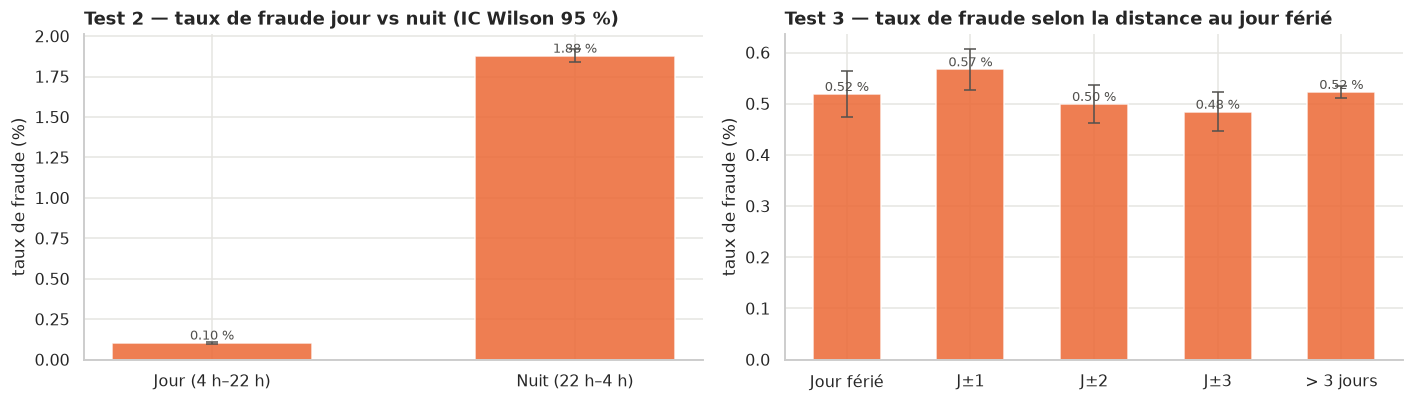

In [3]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * centre, 100 * half


night = silver.groupBy("is_night").agg(F.sum("is_fraud").alias("k"), F.count("*").alias("n")).toPandas().sort_values("is_night")
hol = silver.groupBy("days_to_holiday").agg(F.sum("is_fraud").alias("k"), F.count("*").alias("n")).toPandas().sort_values("days_to_holiday")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, pdf, labels, title in [
    (axes[0], night, ["Jour (4 h–22 h)", "Nuit (22 h–4 h)"], "Test 2 — taux de fraude jour vs nuit (IC Wilson 95 %)"),
    (axes[1], hol, ["Jour férié", "J±1", "J±2", "J±3", "> 3 jours"], "Test 3 — taux de fraude selon la distance au jour férié"),
]:
    centre, half = wilson(pdf["k"].to_numpy(), pdf["n"].to_numpy())
    ax.bar(labels, centre, yerr=half, color=FRAUD, alpha=0.85, width=0.55, capsize=4, error_kw={"lw": 1, "ecolor": "#52514e"})
    for x, v in enumerate(centre):
        ax.text(x, v, f"{v:.2f} %", ha="center", va="bottom", fontsize=8.5, color="#52514e")
    ax.set_title(title)
    ax.set_ylabel("taux de fraude (%)")
plt.tight_layout()
plt.show()

### 📊 Interprétation

- **Test 1 — montant** : $H_0$ rejetée avec un effet **fort** ($r = 0{,}67$). Ce n'est pas un artefact de la taille d'échantillon :
  une fraude tirée au hasard a un montant supérieur à une transaction légitime tirée au hasard dans **83 %** des cas ($\frac{1+r}{2}$).
- **Test 2 — nuit** : $H_0$ rejetée. Le **risque relatif ≈ 18** (1,88 % de fraude la nuit contre 0,105 % le jour) est
  opérationnellement énorme, alors que le V de Cramér (0,10) paraît « faible » : le V est mécaniquement plafonné quand une classe
  est très rare. D'où l'intérêt de toujours rapporter **aussi** un effet métier (risque relatif).
- **Test 3 — jours fériés (apport de la source n°2)** : $H_0$ **non rejetée** (p = 0,61, RR = 0,99, V ≈ 0). Résultat négatif mais
  précieux : sur ces données, **la proximité d'un jour férié n'augmente pas le risque** — le volume légitime et la fraude augmentent
  dans les mêmes proportions. Aucune règle anti-fraude spécifique aux fêtes n'est justifiée ; le test évite une fausse bonne idée.
- **Test 4 — catégories** : $H_0$ rejetée avec un effet **très fort** (ε² = 0,90) : les fraudes `shopping_net` / `shopping_pos` /
  `misc_net` visent ≈ 800 – 1 000 $, celles de `gas_transport` / `grocery_net` / `misc_pos` ≈ 10 $ (tests de carte). Un seuil de montant **unique** serait donc inadapté :
  les règles doivent être **conditionnées par catégorie**.

---
## 2. Segmentation des porteurs de carte (K-Means)

**Entité segmentée :** la carte (`card_id`, 999 porteurs). **Principe clé :** les features décrivent le comportement **légitime** de
chaque porteur (ses transactions frauduleuses sont exclues du profil), puis on mesure *a posteriori* l'exposition de chaque segment
à la fraude. On répond ainsi à la question : *« quels profils de clients sont les plus ciblés ? »* sans que la fraude ne déforme les profils.

| Feature | Définition | Traitement |
|---|---|---|
| `tx_per_month` | transactions légitimes / mois actif | `log1p` si asymétrique |
| `median_amt` | montant médian | `log1p` si asymétrique |
| `online_share` | part d'achats e-commerce | — (borné 0–1) |
| `night_share` | part d'achats nocturnes | — (borné 0–1) |
| `age` | âge du porteur | — |

In [4]:
GOLD_SEGMENTS_PATH = f"{GOLD_ROOT}/card_segments"
FEATURES = ["tx_per_month", "median_amt", "online_share", "night_share", "age"]

legit_profile = (
    silver.filter("is_fraud = 0")
    .groupBy("card_id")
    .agg(
        F.count("*").alias("n_legit_txn"),
        F.countDistinct("trans_month").alias("n_months"),
        F.percentile_approx("amt", 0.5).alias("median_amt"),
        F.avg("is_online").alias("online_share"),
        F.avg("is_night").alias("night_share"),
        F.max("age").alias("age"),
        F.first("state").alias("state"),
        F.first("gender").alias("gender"),
    )
    .withColumn("tx_per_month", F.col("n_legit_txn") / F.col("n_months"))
)
fraud_exposure = silver.groupBy("card_id").agg(
    F.count("*").alias("n_txn_total"),
    F.sum("is_fraud").alias("n_fraud"),
    F.round(F.sum(F.when(F.col("is_fraud") == 1, F.col("amt")).otherwise(0)), 2).alias("fraud_amount"),
)
entities_pd = legit_profile.join(fraud_exposure, "card_id", "left").toPandas().sort_values("card_id").reset_index(drop=True)
fraud_only_cards = fraud_exposure.join(legit_profile, "card_id", "left_anti")
n_fraud_only = fraud_only_cards.count()
print(f"Cartes avec un historique légitime (segmentables) : {len(entities_pd):,}")
print(f"Cartes sans AUCUNE transaction légitime (100 % fraude) : {n_fraud_only:,} — "
      f"{fraud_only_cards.agg(F.sum('n_fraud')).first()[0]:,} fraudes, exclues du K-Means et traitées à part")

# Prétraitement : log1p uniquement sur les features positives asymétriques (|skew| > 1), puis centrage-réduction
skews = entities_pd[FEATURES].skew()
LOG_FEATURES = [f for f in FEATURES if skews[f] > 1 and (entities_pd[f] >= 0).all()]
X = entities_pd[FEATURES].astype(float).copy()
X[LOG_FEATURES] = np.log1p(X[LOG_FEATURES])
X_scaled = StandardScaler().fit_transform(X)
print("Skewness des features :", skews.round(2).to_dict())
print("Features passées en log1p :", LOG_FEATURES)

# Choix de k : silhouette (cohésion/séparation) + inertie (méthode du coude)
k_scan = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_scaled)
    k_scan.append({"k": k, "inertie": km.inertia_, "silhouette": silhouette_score(X_scaled, km.labels_)})
k_scan = pd.DataFrame(k_scan)
# Règle de parcimonie : le plus petit k >= 3 dont la silhouette est à moins de 0,01 du maximum
best_sil = k_scan["silhouette"].max()
best_k = int(k_scan.loc[(k_scan["k"] >= 3) & (k_scan["silhouette"] >= best_sil - 0.01), "k"].min())
display(k_scan.style.hide(axis="index").format({"inertie": "{:,.0f}", "silhouette": "{:.3f}"})
        .apply(lambda r: ["background-color: #eb683433" if r["k"] == best_k else "" for _ in r], axis=1))
print(f"k retenu = {best_k} : silhouette {k_scan.set_index('k').loc[best_k, 'silhouette']:.3f} "
      f"(max {best_sil:.3f}) — au-delà, le gain de qualité est négligeable et la typologie devient illisible")

Cartes avec un historique légitime (segmentables) : 908


Cartes sans AUCUNE transaction légitime (100 % fraude) : 91 — 904 fraudes, exclues du K-Means et traitées à part
Skewness des features : {'tx_per_month': 0.5, 'median_amt': 1.0, 'online_share': 0.08, 'night_share': 0.16, 'age': 0.45}
Features passées en log1p : ['median_amt']


k,inertie,silhouette
2,"2,824",0.337
3,"2,189",0.346
4,"1,810",0.359
5,"1,475",0.353
6,"1,255",0.352
7,"1,093",0.363
8,986,0.354


k retenu = 4 : silhouette 0.359 (max 0.363) — au-delà, le gain de qualité est négligeable et la typologie devient illisible


In [5]:
kmeans = KMeans(n_clusters=best_k, n_init=50, random_state=42).fit(X_scaled)
entities_pd["cluster_id"] = kmeans.labels_

# Nommage métier automatique : les 2 features les plus discriminantes de chaque centroïde (en écarts-types)
LABELS = {
    ("tx_per_month", +1): "Très actifs", ("tx_per_month", -1): "Occasionnels",
    ("median_amt", +1): "Gros paniers", ("median_amt", -1): "Petits paniers",
    ("online_share", +1): "Connectés e-commerce", ("online_share", -1): "Achats en magasin",
    ("night_share", +1): "Noctambules", ("night_share", -1): "Diurnes",
    ("age", +1): "Seniors", ("age", -1): "Jeunes",
}
centers = pd.DataFrame(kmeans.cluster_centers_, columns=FEATURES)
segment_names, used = {}, set()
for cid, row in centers.iterrows():
    top = row.abs().sort_values(ascending=False).index[:2]
    name = " · ".join(LABELS[(f, 1 if row[f] > 0 else -1)] for f in top)
    if name in used:
        name = f"{name} ({cid})"
    used.add(name)
    segment_names[cid] = name
entities_pd["segment"] = entities_pd["cluster_id"].map(segment_names)

# Coordonnées ACP 2D pour la visualisation
pca = PCA(n_components=2, random_state=42).fit(X_scaled)
entities_pd[["pc1", "pc2"]] = pca.transform(X_scaled)
print(f"Variance expliquée par l'ACP 2D : {100 * pca.explained_variance_ratio_.sum():.1f} %")

segment_profiles = (
    entities_pd.groupby("segment")
    .agg(n_cards=("card_id", "count"), tx_per_month=("tx_per_month", "median"), median_amt=("median_amt", "median"),
         online_share=("online_share", "median"), night_share=("night_share", "median"), age=("age", "median"),
         n_txn=("n_txn_total", "sum"), n_fraud=("n_fraud", "sum"), fraud_amount=("fraud_amount", "sum"),
         cards_hit=("n_fraud", lambda s: (s > 0).mean()))
    .assign(fraud_rate_pct=lambda d: 100 * d["n_fraud"] / d["n_txn"],
            share_cards_pct=lambda d: 100 * d["n_cards"] / d["n_cards"].sum(),
            share_losses_pct=lambda d: 100 * d["fraud_amount"] / d["fraud_amount"].sum(),
            cards_hit_pct=lambda d: 100 * d["cards_hit"])
    .drop(columns="cards_hit")
    .sort_values("fraud_rate_pct", ascending=False)
    .reset_index()
)
display(segment_profiles.style.hide(axis="index").format(precision=2).background_gradient(subset=["fraud_rate_pct"], cmap="Oranges"))

assert "segment" in entities_pd.columns, "Ajoutez une colonne lisible `segment` décrivant chaque cluster."
cols_out = ["card_id", "segment", "cluster_id", *FEATURES, "state", "gender", "n_txn_total", "n_fraud", "fraud_amount", "pc1", "pc2"]
(
    spark.createDataFrame(spark_friendly(entities_pd[cols_out]))
    .coalesce(2).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_SEGMENTS_PATH)
)
GOLD_CATALOG.append({"table_name": "card_segments", "path": GOLD_SEGMENTS_PATH,
                     "description": "Segment K-Means de chaque carte (profil légitime) + exposition à la fraude + coordonnées ACP.",
                     "sql": "KMeans(k=%d) sur %s ; log1p(%s) + StandardScaler ; nommage par centroïdes" % (best_k, FEATURES, LOG_FEATURES),
                     "producer": "J4_Stats_Segmentation_Dashboard"})
print(f"Table de segmentation enregistrée dans {GOLD_SEGMENTS_PATH} ({len(entities_pd):,} entités) !")
save_gold_pd(segment_profiles, "segment_profiles", "Profil médian et exposition à la fraude de chaque segment de porteurs.",
             "groupby(segment) : médianes des features, taux de fraude, parts de cartes et de pertes")

Variance expliquée par l'ACP 2D : 71.8 %


segment,n_cards,tx_per_month,median_amt,online_share,night_share,age,n_txn,n_fraud,fraud_amount,fraud_rate_pct,share_cards_pct,share_losses_pct,cards_hit_pct
Gros paniers · Jeunes,95,60.79,76.17,0.15,0.24,38.00,169942,996,559510.17,0.59,10.46,12.24,98.95
Seniors · Noctambules,399,60.71,42.09,0.14,0.26,63.00,645881,3727,2085228.70,0.58,43.94,45.62,97.99
Petits paniers · Diurnes,275,91.25,35.24,0.16,0.22,36.00,676963,2832,1441010.17,0.42,30.29,31.52,97.09
Connectés e-commerce · Diurnes,139,91.17,53.75,0.21,0.21,35.00,358704,1192,485343.34,0.33,15.31,10.62,95.68


Table de segmentation enregistrée dans /lakehouse/gold/card_segments (908 entités) !


🥇 /lakehouse/gold/segment_profiles                4 lignes


'/lakehouse/gold/segment_profiles'

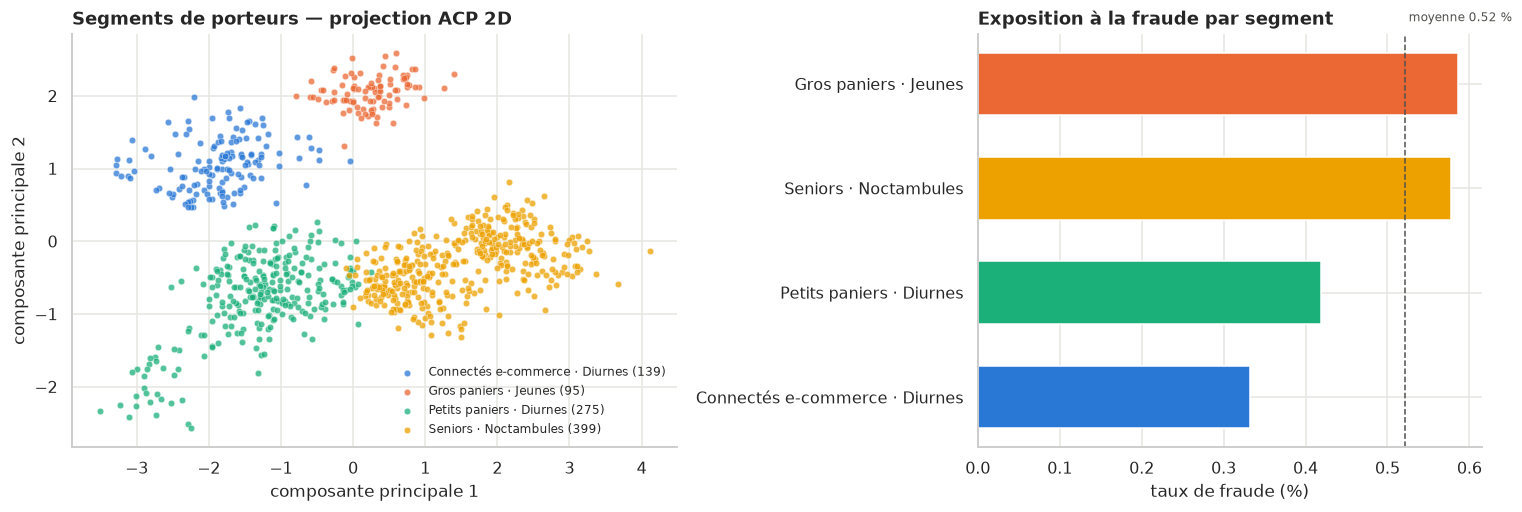

In [6]:
SEG_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
seg_order = segment_profiles["segment"].tolist()
palette = {s: SEG_COLORS[i % len(SEG_COLORS)] for i, s in enumerate(sorted(seg_order))}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
for seg in sorted(seg_order):
    sub = entities_pd[entities_pd["segment"] == seg]
    ax.scatter(sub["pc1"], sub["pc2"], s=18, alpha=0.75, color=palette[seg], label=f"{seg} ({len(sub)})", edgecolor="white", lw=0.3)
ax.set_title("Segments de porteurs — projection ACP 2D")
ax.set_xlabel("composante principale 1")
ax.set_ylabel("composante principale 2")
ax.legend(fontsize=8, loc="best")

ax = axes[1]
sp = segment_profiles.sort_values("fraud_rate_pct")
ax.barh(sp["segment"], sp["fraud_rate_pct"], color=[palette[s] for s in sp["segment"]], height=0.6)
base = 100 * silver.agg(F.avg("is_fraud")).first()[0]
ax.axvline(base, color="#52514e", ls="--", lw=1)
ax.text(base, len(sp) - 0.4, f" moyenne {base:.2f} %", fontsize=8, color="#52514e")
ax.set_title("Exposition à la fraude par segment")
ax.set_xlabel("taux de fraude (%)")
plt.tight_layout()
plt.show()

> **Lecture métier.**
> - **91 cartes « 100 % fraude »** (aucune transaction légitime) : typiques de cartes **compromises dès leur émission** ou de numéros
>   générés. Elles sont exclues de la segmentation comportementale et relèvent d'un contrôle à l'**ouverture de compte**.
> - Les 4 segments se distinguent par le **niveau d'activité** (≈ 61 vs ≈ 91 transactions/mois en médiane), l'**âge** (≈ 35 vs ≈ 63 ans),
>   le **panier médian** (35 à 76 $) et la part d'achats **e-commerce**.
> - **Presque toutes les cartes (≈ 97 %) subissent au moins une fraude**, avec un nombre de fraudes par carte quasi constant (≈ 9 – 10) :
>   les fraudeurs ne choisissent pas leurs victimes selon leur profil. En revanche, le **taux** de fraude est 1,4 à 1,8× plus élevé chez les
>   porteurs **peu actifs** (≈ 0,58 % contre 0,33 – 0,42 %), car la même rafale frauduleuse pèse bien plus dans un historique court.
> - **Recommandation** : des seuils d'alerte **relatifs à l'historique de chaque carte** (vélocité, ratio au panier habituel), plus
>   discriminants qu'un seuil global — c'est exactement ce que capturent `amt_sum_24h` et `amt_ratio_to_card_mean` dans le modèle ci-dessous.

---
## 3. 🤖 Bonus métier : modèle de scoring de fraude (Spark MLlib)

**Protocole d'évaluation réaliste :**
- **Découpage temporel** : apprentissage sur `fraud_train.csv` (jan. 2019 → juin 2020), évaluation sur `fraud_test.csv`
  (juin → déc. 2020). Le modèle est jugé sur des transactions **futures**, comme en production.
- **Déséquilibre** : sous-échantillonnage des légitimes à 10 % **dans le train uniquement** ; le test garde sa prévalence réelle (0,39 %).
- **Métrique** : **PR-AUC** (aire sous la courbe précision-rappel). La ROC-AUC est trompeuse sur classe rare : avec 99,6 % de
  négatifs, un faible taux de faux positifs représente quand même des milliers d'alertes inutiles.
- **Modèle** : *Gradient-Boosted Trees* (non-linéarités et interactions « nuit × e-commerce × montant » capturées sans normalisation).

In [7]:
from pyspark.ml import Pipeline
from pyspark.ml.classification import GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array

NUM_FEATURES = ["amt_log", "hour", "is_night", "is_weekend", "is_online", "age", "distance_km", "city_pop_log",
                "txn_count_24h", "amt_sum_24h", "secs_since_prev_txn", "amt_ratio_to_card_mean", "days_to_holiday"]
CAT_FEATURES = ["category", "gender"]

model_df = silver.select(*NUM_FEATURES, *CAT_FEATURES, "amt", "dataset_split", F.col("is_fraud").cast("double").alias("label"))
train = model_df.filter("dataset_split = 'train'").sampleBy("label", fractions={0.0: 0.10, 1.0: 1.0}, seed=42).cache()
test = model_df.filter("dataset_split = 'test'")
print(f"Train (sous-échantillonné) : {train.count():,} lignes, {100 * train.agg(F.avg('label')).first()[0]:.1f} % de fraudes")

pipeline = Pipeline(stages=[
    *[StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in CAT_FEATURES],
    VectorAssembler(inputCols=NUM_FEATURES + [f"{c}_idx" for c in CAT_FEATURES], outputCol="features"),
    GBTClassifier(labelCol="label", featuresCol="features", maxIter=60, maxDepth=5, stepSize=0.1, maxBins=32, seed=42),
])
model = pipeline.fit(train)

pred = model.transform(test).withColumn("p_fraud", vector_to_array("probability")[1]).select("label", "amt", "p_fraud", "rawPrediction").cache()
pr_auc = BinaryClassificationEvaluator(metricName="areaUnderPR").evaluate(pred)
roc_auc = BinaryClassificationEvaluator(metricName="areaUnderROC").evaluate(pred)
prevalence = pred.agg(F.avg("label")).first()[0]
print(f"Test : {pred.count():,} transactions | prévalence {100 * prevalence:.2f} %")
print(f"PR-AUC  = {pr_auc:.3f}   (référence aléatoire = {prevalence:.4f}, soit ×{pr_auc / prevalence:,.0f})")
print(f"ROC-AUC = {roc_auc:.4f}")

model.write().overwrite().save("/lakehouse/models/fraud_gbt_v1")
print("Modèle versionné sur HDFS : /lakehouse/models/fraud_gbt_v1")

Train (sous-échantillonné) : 136,538 lignes, 5.5 % de fraudes


netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


Test : 555,719 transactions | prévalence 0.39 %
PR-AUC  = 0.893   (référence aléatoire = 0.0039, soit ×231)
ROC-AUC = 0.9953


Modèle versionné sur HDFS : /lakehouse/models/fraud_gbt_v1


In [8]:
# Courbe de seuil : un seul passage Spark calcule la matrice de confusion pour 49 seuils
thresholds = np.round(np.arange(0.02, 0.99, 0.02), 2)
exprs = []
for i, t in enumerate(thresholds):
    hit = F.col("p_fraud") >= float(t)
    exprs += [
        F.sum((hit & (F.col("label") == 1)).cast("int")).alias(f"tp_{i}"),
        F.sum((hit & (F.col("label") == 0)).cast("int")).alias(f"fp_{i}"),
        F.sum(F.when(hit & (F.col("label") == 1), F.col("amt")).otherwise(0)).alias(f"amt_{i}"),
    ]
agg = pred.agg(F.sum("label").alias("pos"), F.count("*").alias("n"),
               F.sum(F.when(F.col("label") == 1, F.col("amt")).otherwise(0)).alias("fraud_amt"), *exprs).first()
P, N_TOT, FRAUD_AMT = int(agg["pos"]), int(agg["n"]), float(agg["fraud_amt"])

curve = pd.DataFrame({
    "threshold": thresholds,
    "tp": [agg[f"tp_{i}"] for i in range(len(thresholds))],
    "fp": [agg[f"fp_{i}"] for i in range(len(thresholds))],
    "amt_caught": [float(agg[f"amt_{i}"]) for i in range(len(thresholds))],
})
curve["fn"] = P - curve["tp"]
curve["tn"] = (N_TOT - P) - curve["fp"]
curve["alerts"] = curve["tp"] + curve["fp"]
curve["precision"] = curve["tp"] / curve["alerts"].replace(0, np.nan)
curve["recall"] = curve["tp"] / P
curve["f1"] = 2 * curve["precision"] * curve["recall"] / (curve["precision"] + curve["recall"])
curve["amt_missed"] = FRAUD_AMT - curve["amt_caught"]
curve["amt_caught_share"] = curve["amt_caught"] / FRAUD_AMT
curve = curve.fillna({"precision": 1.0, "f1": 0.0})

best = curve.loc[curve["f1"].idxmax()]
print(f"Seuil optimal (F1 max) = {best['threshold']:.2f} → précision {best['precision']:.1%}, rappel {best['recall']:.1%}, "
      f"{int(best['alerts']):,} alertes pour {N_TOT:,} transactions ({100 * best['alerts'] / N_TOT:.2f} %)")
print(f"Montant fraudé intercepté : {best['amt_caught']:,.0f} $ sur {FRAUD_AMT:,.0f} $ ({best['amt_caught_share']:.1%})")

gbt = model.stages[-1]
importance = (
    pd.DataFrame({"feature": NUM_FEATURES + [f"{c}_idx" for c in CAT_FEATURES], "importance": gbt.featureImportances.toArray()})
    .assign(feature=lambda d: d["feature"].str.replace("_idx", "", regex=False))
    .sort_values("importance", ascending=False)
)
metrics = pd.DataFrame([{
    "model": "GBTClassifier (Spark MLlib)", "version": "fraud_gbt_v1", "train_period": "2019-01 → 2020-06",
    "test_period": "2020-06 → 2020-12", "n_test": N_TOT, "n_test_fraud": P, "prevalence": prevalence,
    "pr_auc": pr_auc, "roc_auc": roc_auc, "best_threshold": float(best["threshold"]),
    "precision_at_best": float(best["precision"]), "recall_at_best": float(best["recall"]), "f1_at_best": float(best["f1"]),
    "fraud_amount_test": FRAUD_AMT,
}])
save_gold_pd(metrics, "model_metrics", "Métriques du modèle de scoring sur la période de test (PR-AUC, ROC-AUC, seuil optimal).",
             "GBTClassifier(maxIter=60, maxDepth=5) ; train sous-échantillonné 10 % ; évaluation temporelle hors échantillon")
save_gold_pd(curve, "model_threshold_curve", "Matrice de confusion, précision, rappel et montants interceptés pour 49 seuils de score.",
             "Agrégation Spark unique : SUM(CASE WHEN p_fraud >= t ...) pour t = 0.02 … 0.98")
save_gold_pd(importance, "model_feature_importance", "Importance des variables du modèle GBT (réduction d'impureté).",
             "GBTClassificationModel.featureImportances")

Seuil optimal (F1 max) = 0.90 → précision 88.9%, rappel 77.7%, 1,874 alertes pour 555,719 transactions (0.34 %)
Montant fraudé intercepté : 976,638 $ sur 1,133,325 $ (86.2%)


🥇 /lakehouse/gold/model_metrics                   1 lignes


🥇 /lakehouse/gold/model_threshold_curve          49 lignes


🥇 /lakehouse/gold/model_feature_importance       15 lignes


'/lakehouse/gold/model_feature_importance'

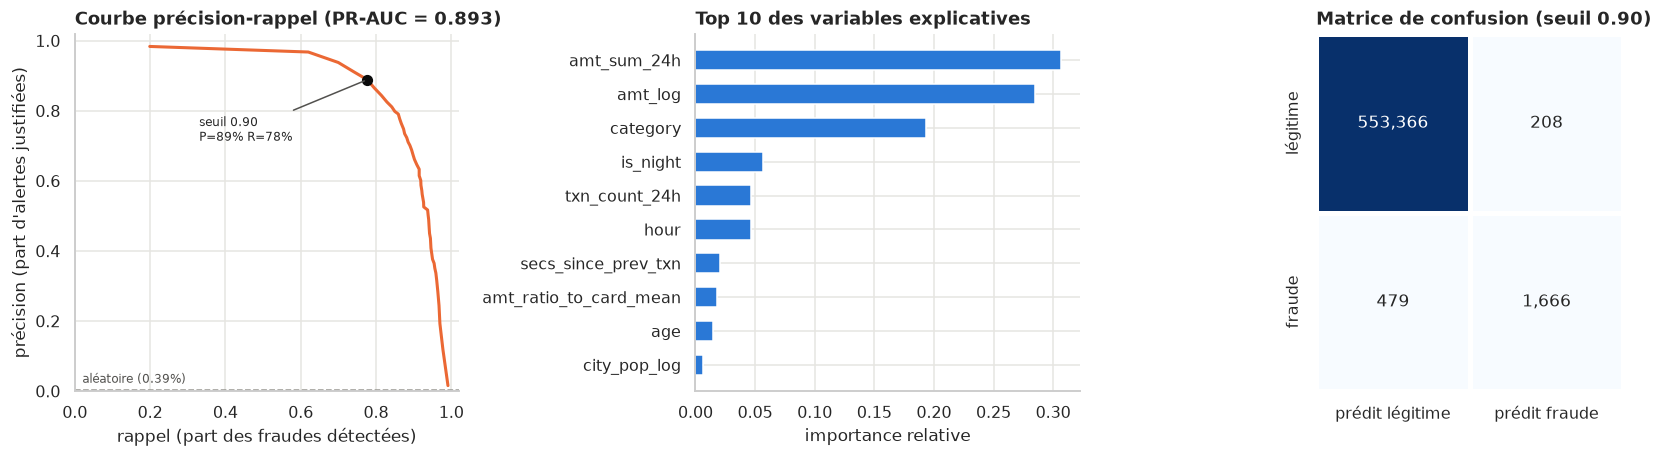

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1, 1, 0.8]})

ax = axes[0]
ax.plot(curve["recall"], curve["precision"], color=FRAUD, lw=2)
ax.scatter([best["recall"]], [best["precision"]], color="#0b0b0b", zorder=3, s=40)
ax.annotate(f"seuil {best['threshold']:.2f}\nP={best['precision']:.0%} R={best['recall']:.0%}",
            (best["recall"], best["precision"]), xytext=(-110, -40), textcoords="offset points", fontsize=8,
            arrowprops={"arrowstyle": "-", "color": "#52514e"})
ax.axhline(prevalence, color=NEUTRAL, ls="--", lw=1)
ax.text(0.02, prevalence + 0.02, f"aléatoire ({prevalence:.2%})", fontsize=8, color="#52514e")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.set_title(f"Courbe précision-rappel (PR-AUC = {pr_auc:.3f})")
ax.set_xlabel("rappel (part des fraudes détectées)")
ax.set_ylabel("précision (part d'alertes justifiées)")

ax = axes[1]
top_imp = importance.head(10).iloc[::-1]
ax.barh(top_imp["feature"], top_imp["importance"], color=LEGIT, height=0.6)
ax.set_title("Top 10 des variables explicatives")
ax.set_xlabel("importance relative")

ax = axes[2]
cm = np.array([[best["tn"], best["fp"]], [best["fn"], best["tp"]]], dtype=float)
sns.heatmap(cm, annot=[[f"{int(v):,}" for v in r] for r in cm], fmt="", cmap="Blues", cbar=False, linewidths=2,
            linecolor="white", xticklabels=["prédit légitime", "prédit fraude"], yticklabels=["légitime", "fraude"], ax=ax)
ax.set_title(f"Matrice de confusion (seuil {best['threshold']:.2f})")
plt.tight_layout()
plt.show()

> **Lecture.** Le modèle atteint une **PR-AUC de 0,89** sur 555 719 transactions futures (×231 par rapport au hasard). Au seuil qui
> maximise le F1 (0,90) : **78 % des fraudes détectées** et **86 % du montant fraudé intercepté**, avec **89 % d'alertes justifiées**
> — soit seulement 1 874 alertes (0,34 % des transactions) à investiguer sur six mois. Les variables dominantes confirment l'analyse
> statistique : **montant**, **vélocité 24 h** (`amt_sum_24h`, feature construite au Jour 2), **catégorie** et **heure / nuit**. Le **seuil** est une décision métier, pas statistique : le dashboard
> permet de le faire varier et d'en voir l'impact sur la charge d'investigation et les pertes évitées.
>
> ⚠️ Le sous-échantillonnage gonfle les probabilités (le modèle a vu 5 % de fraudes au lieu de 0,5 %) : les scores sont des **rangs de
> risque**, à recalibrer (*Platt* / isotonique) avant toute interprétation comme probabilité réelle.

---
## 4. Livrable final : dashboard Streamlit (`app/dashboard.py`, port `8501`)

Le dashboard **FraudLake** lit **exclusivement** la couche Gold (y compris `data_catalog` pour afficher la requête et la
justification de chaque graphique) et propose : KPI, pertes et Pareto par catégorie, carte de chaleur horaire, carte des États,
segments de porteurs, simulateur de seuil du modèle et synthèse des tests statistiques.

In [10]:
# Mise à jour du catalogue de données (MERGE : idempotent si le notebook est rejoué)
from delta.tables import DeltaTable

catalog_path = f"{GOLD_ROOT}/data_catalog"
updates = spark.createDataFrame(spark_friendly(pd.DataFrame(GOLD_CATALOG))).withColumn("updated_at", F.current_timestamp())
if DeltaTable.isDeltaTable(spark, catalog_path):
    (DeltaTable.forPath(spark, catalog_path).alias("c")
     .merge(updates.alias("u"), "c.table_name = u.table_name")
     .whenMatchedUpdateAll().whenNotMatchedInsertAll().execute())
else:
    updates.write.format("delta").save(catalog_path)

# Vérification finale de l'inventaire complet de la couche Gold sur HDFS
jvm = spark._jvm
fs = jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())
PathHDFS = jvm.org.apache.hadoop.fs.Path
gold_root = PathHDFS(GOLD_ROOT)

gold_tables = [
    s.getPath().getName()
    for s in fs.listStatus(gold_root)
    if s.isDirectory() and fs.exists(PathHDFS(s.getPath(), "_delta_log"))
]
assert len(gold_tables) > 0, "Aucune table Delta trouvée dans /lakehouse/gold/ !"

print("=== Tables Delta disponibles dans /lakehouse/gold/ pour Streamlit ===")
for t in sorted(gold_tables):
    cnt = spark.read.format("delta").load(f"{GOLD_ROOT}/{t}").count()
    print(f" - {GOLD_ROOT}/{t:<26} : {cnt:>9,} lignes")

=== Tables Delta disponibles dans /lakehouse/gold/ pour Streamlit ===


 - /lakehouse/gold/amount_distribution        :         3 lignes


 - /lakehouse/gold/card_segments              :       908 lignes


 - /lakehouse/gold/data_catalog               :        13 lignes


 - /lakehouse/gold/fraud_by_category          :        14 lignes


 - /lakehouse/gold/fraud_by_state             :        51 lignes


... (5 outputs left out)

 - /lakehouse/gold/model_threshold_curve      :        49 lignes


 - /lakehouse/gold/segment_profiles           :         4 lignes


 - /lakehouse/gold/stat_tests                 :         4 lignes


 - /lakehouse/gold/transactions_sample        :    46,606 lignes


---
## 🏁 Conclusions & recommandations

| # | Constat (prouvé) | Recommandation opérationnelle |
|---|---|---|
| 1 | Fraude nocturne : risque ×18 entre 22 h et 4 h | Authentification forte systématique au-delà d'un montant la nuit |
| 2 | Montant fraudé médian ≈ 8× le légitime, mais dépendant de la catégorie | Seuils de montant **par catégorie** (pas de seuil global) |
| 3 | Catégories e-commerce + `grocery_pos` = cœur des pertes (Pareto) | Renforcer 3-D Secure sur `shopping_net` / `misc_net` |
| 4 | Jours fériés : pas d'effet de risque significatif | Pas de règle spécifique fêtes ; suivre le **taux**, pas le volume |
| 5 | Taux de fraude 1,4 à 1,8× plus élevé chez les porteurs peu actifs ; 91 cartes 100 % frauduleuses | Seuils relatifs à l'historique de la carte ; contrôle renforcé à l'émission |
| 6 | Modèle GBT : PR-AUC = 0,89, 86 % des montants fraudés interceptés pour 0,34 % d'alertes | Déployer en *scoring* temps réel ; fixer le seuil selon la capacité de l'équipe d'investigation |

**Limites.** Dataset **synthétique** (simulateur Sparkov) : les motifs sont plus nets que dans la réalité ; validation à mener sur données
réelles, avec suivi de dérive (*data drift*) et recalibrage périodique du modèle.

➡️ **Jour 5 — MLOps** : ce modèle est industrialisé dans `J5_MLOps_Industrialisation.ipynb` (suivi MLflow de 5 candidats, portes de
qualité et d'équité, registre `@champion`, API de scoring, file d'alertes expliquée et surveillance de la dérive).